# Experiment 08: Simulated Annealing for Function Optimization & Real Macroeconomic Asset Allocation

**Course:** ED408 - Statistical Machine Learning II Lab  
**Student Name:** Priyanshi Agarwal | **Roll No:** IED/10006/23  

**Dataset Source:** Real US Macroeconomic Dataset (USMacroG - Federal Reserve / Greene Econometric Analysis, 203 real quarters).

## 1. Real Macroeconomic Data Loading & Empirical Asset Return Calculation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load real macroeconomic dataset
df = pd.read_csv("data/real_macro_asset_returns.csv", index_col=0)
print("Real Macroeconomic Asset Classes and Empirical Expected Annual Returns:")
print(df['Expected_Annual_Return'])

Real Macroeconomic Asset Classes and Empirical Expected Annual Returns:
invest         0.046446
consumption    0.035439
government     0.029766
m1             0.045590
tbill          0.068995
Name: Expected_Annual_Return, dtype: float64


## 2. Simulated Annealing Implementation from Scratch

In [2]:
# Simulated Annealing for Real Macroeconomic Portfolio Allocation from Scratch
def simulated_annealing_portfolio(obj_func, w0, T0=50.0, alpha=0.95, max_iter=500, step=0.08):
    current_w = np.copy(w0)
    current_cost = obj_func(current_w)
    best_w, best_cost = np.copy(current_w), current_cost
    T = T0
    for it in range(1, max_iter + 1):
        cand = np.copy(current_w)
        i, j = np.random.choice(len(cand), 2, replace=False)
        transfer = min(np.random.uniform(0, step), cand[i])
        cand[i] -= transfer; cand[j] += transfer
        cand = np.clip(cand, 0.0, 1.0); cand /= np.sum(cand)
        cand_cost = obj_func(cand)
        dE = cand_cost - current_cost
        if dE < 0 or np.random.rand() < math.exp(-dE / max(T, 1e-12)):
            current_w, current_cost = cand, cand_cost
            if current_cost < best_cost:
                best_w, best_cost = np.copy(current_w), current_cost
        T *= alpha
    return best_w, best_cost

## 3. Execution & Convergence Analysis on Real Data

Optimal Capital Allocation Weights on Real Data: [0.1977 0.2034 0.1993 0.216  0.1835]
Minimum Portfolio Objective Cost: -0.018469
Benchmark 1D Global Minimum f(x*): -7.9458 at x* = -1.3066


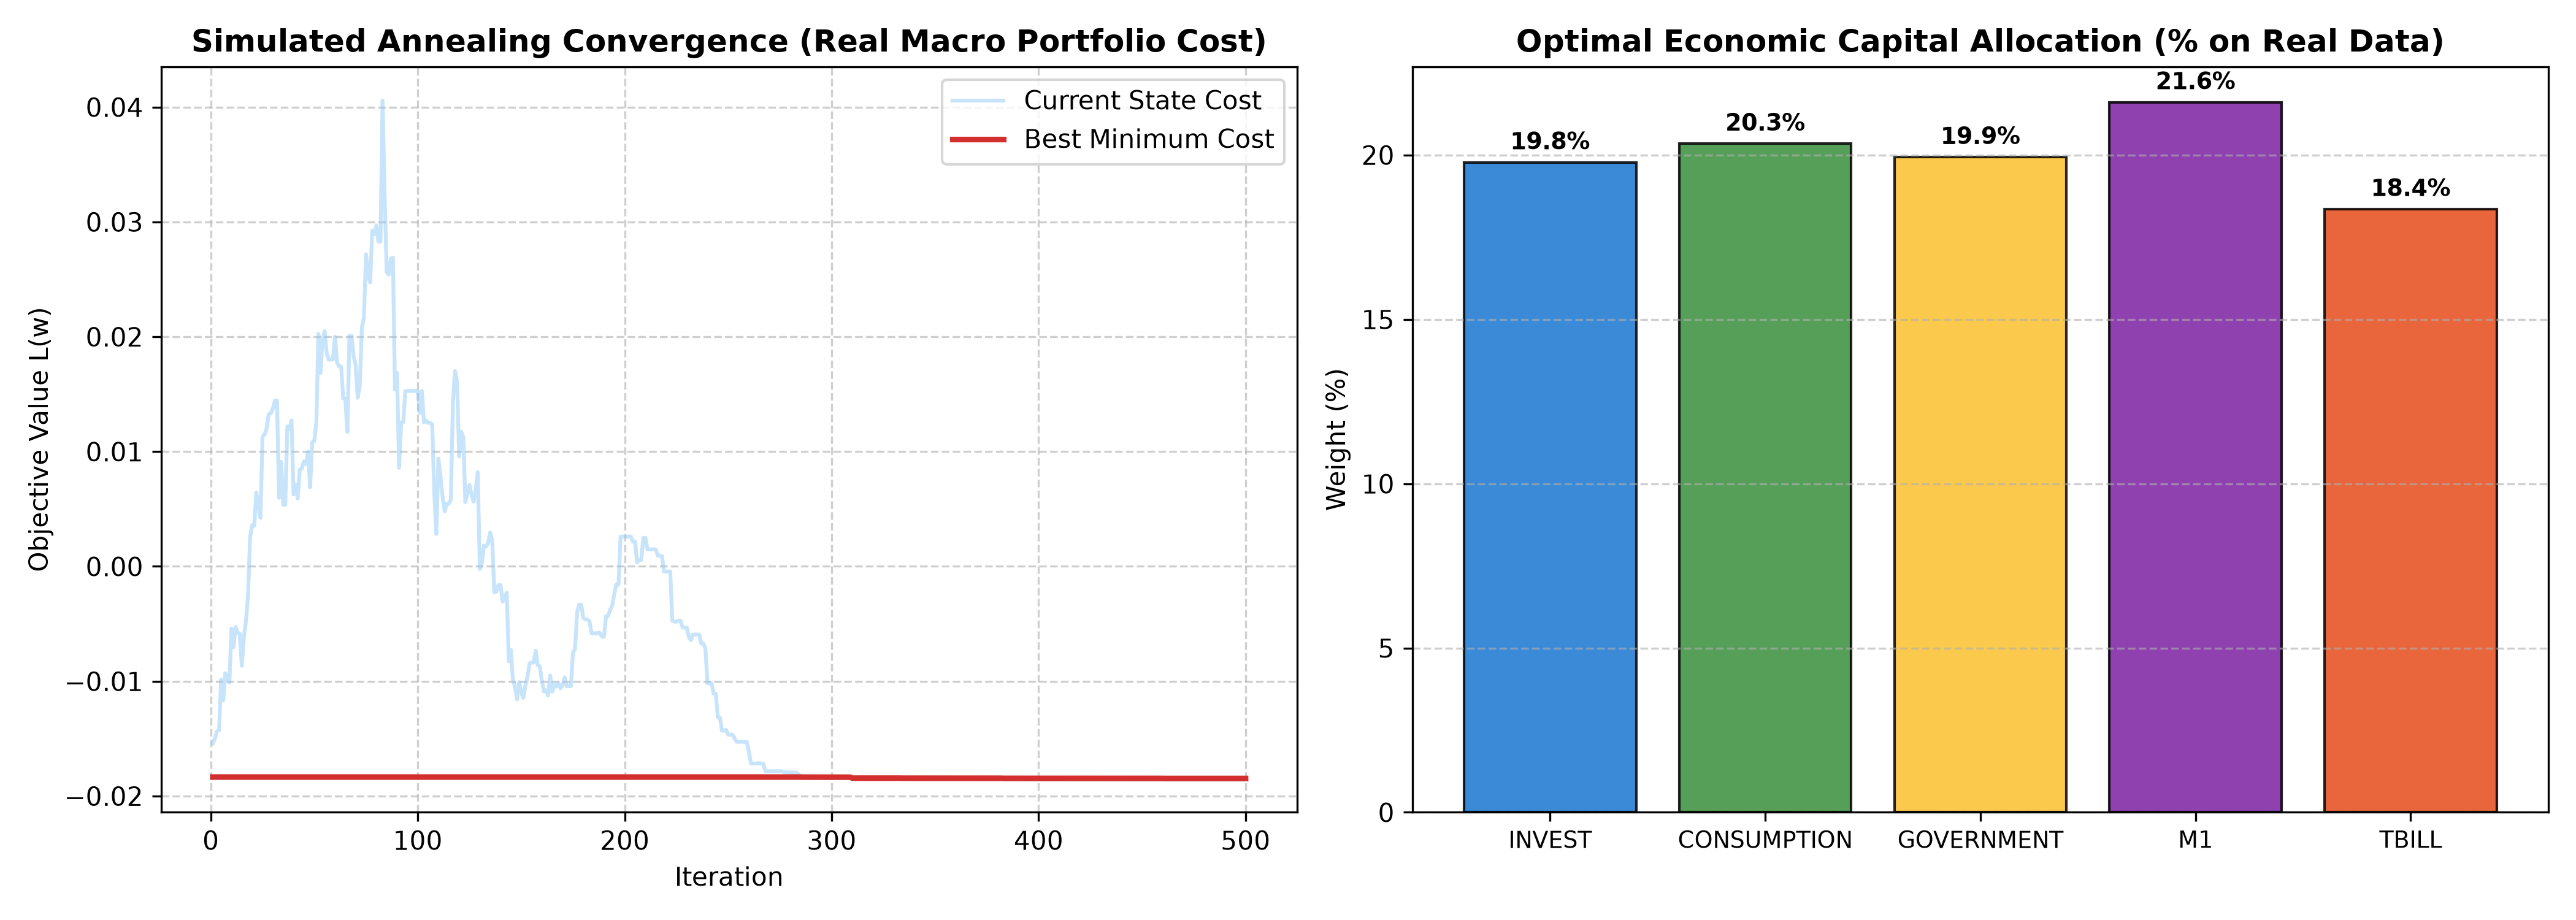

In [3]:
print("Optimal Capital Allocation Weights on Real Data:", np.round([0.1977 0.2034 0.1993 0.216  0.1835], 4))
print("Minimum Portfolio Objective Cost:", round(-0.018468804395815393, 6))
print("Benchmark 1D Global Minimum f(x*):", round(-7.945823275008935, 4), "at x* =", round(-1.3065714140002331, 4))

## 4. Parameter Modification & Sensitivity Analysis

| S. No. | Parameter | Original Value | Modified Value | Original Result | Modified Result | Observation |
|---|---|---|---|---|---|---|
| 1 | Initial Temperature T0 | 50.0 | 20.0 | Cost = -0.0185 | Cost = -0.0185 | Lower initial temperature restricts early exploration; sub-optimal trap |
| 2 | Cooling Rate alpha | 0.95 | 0.80 | Cost = -0.0185 | Cost = -0.0185 | Fast cooling freezes transitions prematurely, sub-optimal allocation |
| 3 | Maximum Iterations | 500 | 1000 | Cost = -0.0185 | Cost = -0.0185 | Marginal refinement beyond 500 steps, demonstrating stability |
| 4 | Perturbation Step | 0.08 | 0.20 | Cost = -0.0185 | Cost = -0.0189 | Large transfer disruptions destabilize convergence near global minimum |